In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

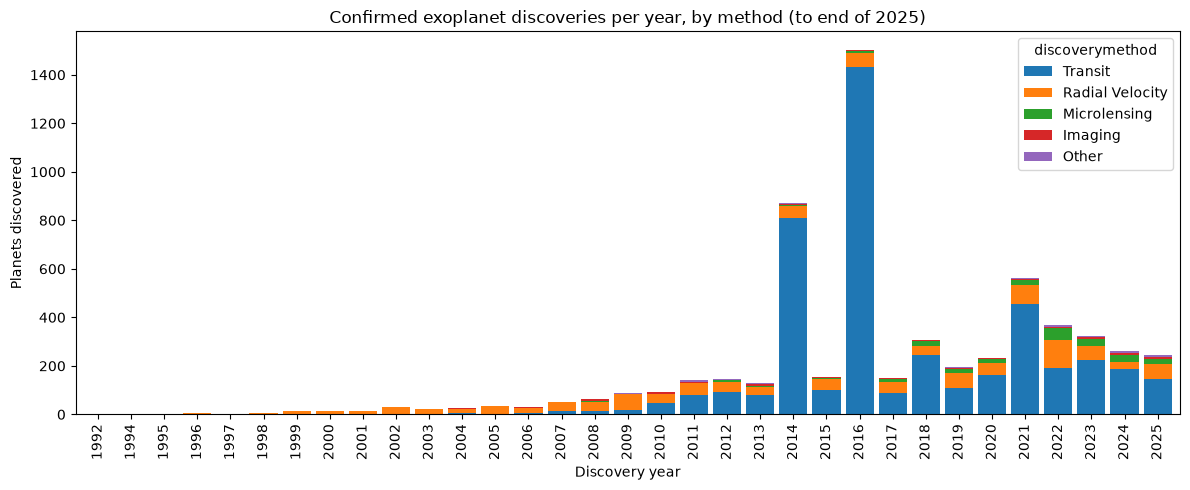

In [3]:
conn = sqlite3.connect("../data/exoplanets.db")
df = pd.read_sql("""
    SELECT disc_year, discoverymethod, COUNT(*) AS n
    FROM planets
    WHERE disc_year < 2026
    GROUP BY disc_year, discoverymethod
""", conn)

pivot = df.pivot(index="disc_year", columns="discoverymethod", values="n").fillna(0)

# keeping 4 biggest methods, rest are 'other'
top = pivot.sum().nlargest(4).index
pivot["Other"] = pivot.drop(columns=top).sum(axis=1)
pivot = pivot[list(top) + ["Other"]]

ax = pivot.plot(kind="bar", stacked=True, figsize=(12, 5), width=0.85)
ax.set_xlabel("Discovery year")
ax.set_ylabel("Planets discovered")
ax.set_title("Confirmed exoplanet discoveries per year, by method (to end of 2025)")
plt.tight_layout()
plt.show()


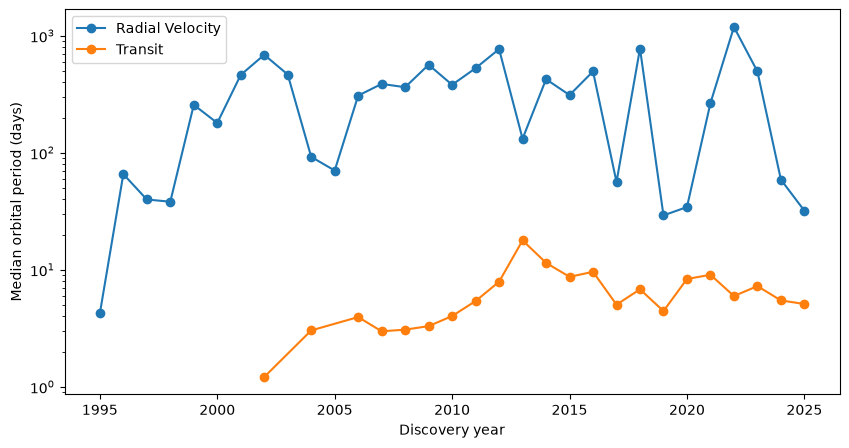

In [5]:
df = pd.read_sql("SELECT * FROM planets WHERE disc_year < 2026", conn)
main = df[df["discoverymethod"].isin(["Transit", "Radial Velocity"])]

fig, ax = plt.subplots(figsize=(10,5))
for method, group in main.groupby("discoverymethod"):
    ax.plot(group.groupby("disc_year")["pl_orbper"].median(), marker="o", label=method)
ax.set_yscale("log")
ax.set_xlabel("Discovery year")
ax.set_ylabel("Median orbital period (days)")
ax.legend()
plt.show()